# DynkinLab Masterclass

## Quasi-Cartan matrices, flation, and the A/D classification

**Abstract.** This masterclass builds the theory from first principles. We start with integer
matrices and quadratic forms, compute inertia exactly, and pass to labeled mixed bigraphs. We
then study flation as a form-preserving change of basis, meet the finite Dynkin types through a
bounded-flation oracle, and prove the A- and D-type structural criteria by computation. Every
figure is laid out by NetworkX and every certificate is checked by the library.

**How to use this notebook.** Run the cells from top to bottom once. The canonical tour is fixed
and always succeeds. The numbered sections build the theory; the parameter labs at the end let
you change path text, flation endpoints, cyclization endpoints, and layout policy without editing
any other cell.

**Roadmap.**

1. Matrices, symmetrizers, quadratic forms, and exact inertia.
2. Labeled matrices, faithful bigraphs, and the drawable range.
3. Flation as a form-preserving change of basis.
4. Finite Dynkin types and the bounded-flation oracle.
5. A-type structure through block-cut trees: $A_9$.
6. D-type gluing through an odd D-core: $D_{13}$.
7. D-type cyclization through an internal path: $A_9$ to $D_8$.
8. The boundary table, exercises, and parameter labs.

**Conventions.** Matrices act on column vectors. The diagonal of a quasi-Cartan matrix is always
$2$. Vertex labels are positive integers in the worked examples. A solid edge has weight $-1$;
a dotted edge has weight $+1$; an arrow carries the same sign convention and a multiplicity.

## Setup

The notebook installs the latest DynkinLab from the project's git default branch when it runs in
Colab. A local checkout skips the installation and imports the package already on the path. No
commit, tag, package version, or dependency version is pinned.

In [1]:
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "-U",
            "dynkinlab @ git+https://github.com/knkillname/dynkinlab.git@main",
        ],
    )

The library owns the reusable notation, table rendering, layout, and drawing. The notebook only
chooses examples, displays results, and asserts invariants. The inline matplotlib backend makes
the committed figures portable; the canonical display options use one-based matrix headers and a
seeded automatic layout.

In [2]:
import matplotlib

matplotlib.use("module://matplotlib_inline.backend_inline")

import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

import dynkinlab
from dynkinlab import (
    Bigraph,
    ClassificationStatus,
    DCore,
    DynkinType,
    EdgeMultiset,
    Inertia,
    QuasiCartanMatrix,
)

dynkinlab.display.options.matrix_index_base = 1
dynkinlab.display.options.bigraph_layout = "auto"
dynkinlab.display.options.bigraph_layout_iterations = 10000
dynkinlab.display.options.bigraph_layout_seed = 7

## 1. Matrices, quadratic forms, and inertia

**Definition 1.1 (quasi-Cartan matrix).** A quasi-Cartan matrix is an integer matrix $A$ with
$A_{ii} = 2$ for every $i$. It is symmetrizable when there are positive integers $d_i$ such that
$S = DA$ is symmetric, where $D = \operatorname{diag}(d_1, \dots, d_n)$.

**Definition 1.2 (quadratic form).** The form attached to $A$ is

$$
q(x) = \frac{1}{2} x^{\mathsf{T}} S x
     = \sum_i d_i x_i^2 + \sum_{i < j} S_{ij} x_i x_j.
$$

**Definition 1.3 (inertia).** The inertia of $S$ is the triple $(p, n, z)$ of positive, negative,
and zero eigenvalue counts. Sylvester's law says it is unchanged by an invertible change of basis.
DynkinLab computes it by exact rational congruence reduction, so a zero eigenvalue is a proved
zero, not a floating-point tolerance.

The first examples are the two smallest $A$-types. The path notation is a DynkinLab input format:
`--` is a solid edge and `..` is a dotted edge. Labels may be pinned explicitly to fix matrix
order.

In [3]:
A2 = Bigraph.from_paths("1--2")
A3 = Bigraph.from_paths("1--2--3")

display(
    HTML(
        '<div style="display:flex;gap:1.5rem;flex-wrap:wrap;">'
        f"<div>{A2.matrix.to_html(labels=A2.labels)}</div>"
        f"<div>{A3.matrix.to_html(labels=A3.labels)}</div>"
        "</div>",
    ),
)
display(Markdown(A2.matrix.quadratic_form.to_markdown()))
display(Markdown(A2.matrix.inertia.to_markdown()))
assert A2.matrix.inertia == Inertia(2, 0, 0)
assert A3.matrix.inertia == Inertia(3, 0, 0)

**Quadratic form**

$$q(x) = \sum_i d_i x_i^2 + \sum_{i<j} s_{ij} x_i x_j$$

$$q(x) = x_0^2 + x_1^2 - x_0 x_1$$

| positive | negative | zero | rank | signature |
|---:|---:|---:|---:|---:|
| 2 | 0 | 0 | 2 | 2 |

positive definite

## 2. Labeled matrices and the drawable range

**Definition 2.1 (mixed bigraph).** A mixed bigraph is a labeled graph whose edges are solid or
dotted and whose arrows carry a positive multiplicity. It is a view of a matrix when each
off-diagonal pair is encoded by the following dictionary. Write
$m = \min(\lvert a\rvert, \lvert b\rvert)$ and $M = \max(\lvert a\rvert, \lvert b\rvert)$.

| pair $(a, b)$ | view |
|---|---|
| $a = b = 0$ | no edge |
| $a = b \ne 0$ | solid edge if negative, dotted edge if positive |
| $m = 1$ and $a \ne b$ | arrow of multiplicity $M$ |

**Proposition 2.2 (drawable range).** A quasi-Cartan matrix has a faithful mixed bigraph exactly
when every off-diagonal pair is zero, is symmetric, or has smaller magnitude one. A positive
definite quasi-Cartan matrix always passes this test, because its two-by-two principal minors
force $4 - ab > 0$. The converse fails: drawability is an entry condition, not a finiteness
condition.

The matrix with opposite entries $2$ and $4$ below is the boundary case. Its entries have
magnitudes $2$ and $4$, so it has no faithful bigraph. It still has an exact inertia and a
classifier outcome, and we display only the matrix.

In [4]:
bad = QuasiCartanMatrix(((2, 2), (4, 2)))
drawable_cases = (("A2", A2.matrix), ("A3", A3.matrix), ("2/4", bad))
drawable_lines = ["| case | faithful bigraph |", "|---|---|"]
for name, matrix in drawable_cases:
    faithful = "yes" if matrix.has_faithful_bigraph else "no"
    drawable_lines.append(f"| {name} | {faithful} |")
display(Markdown("\n".join(drawable_lines)))
display(Markdown("**Matrix-only case: 2/4**\n\n" + bad.to_markdown(labels=(1, 2))))
display(Markdown(bad.inertia.to_markdown()))
display(Markdown(bad.classify().to_markdown()))
bad_bigraph = Bigraph(bad, (1, 2))
try:
    tuple(bad_bigraph.edges)
except ValueError as error:
    display(Markdown(f"**No faithful bigraph:** {error}"))
assert bad.has_faithful_bigraph is False
assert bad.inertia == Inertia(1, 1, 0)
assert bad.classify().status is ClassificationStatus.NOT_ADMISSIBLE

| case | faithful bigraph |
|---|---|
| A2 | yes |
| A3 | yes |
| 2/4 | no |

**Matrix-only case: 2/4**

|   | 1 | 2 |
|---|---:|---:|
| 1 | 2 | 2 |
| 2 | 4 | 2 |

| positive | negative | zero | rank | signature |
|---:|---:|---:|---:|---:|
| 1 | 1 | 0 | 2 | 0 |

indefinite

**Dynkin classification**

**Status:** `NOT_ADMISSIBLE`
**Reason:** off-diagonal magnitude is at least 3

**Inertia**

| positive | negative | zero | rank | signature |
|---:|---:|---:|---:|---:|
| 1 | 1 | 0 | 2 | 0 |

indefinite

**Components**

None.

**Steps:** 0  **Bound:** 0
**Normal form:** none

**No faithful bigraph:** matrix has no faithful bigraph representation

**Figure 1.** The two smallest $A$-types. The positions come from the automatic NetworkX layout;
no coordinates are stored in the notebook.

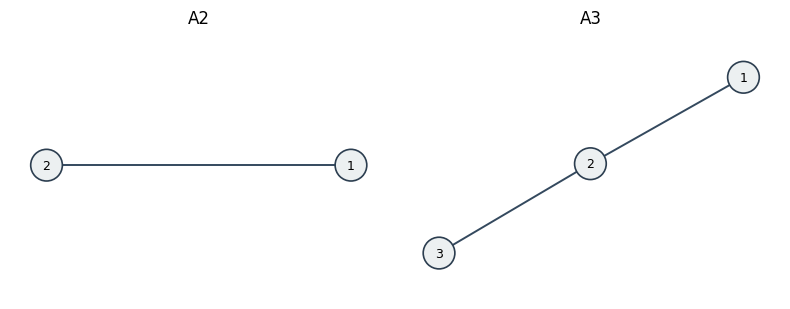

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(8.0, 3.2))
A2.draw(ax=axes[0], title="A2")
A3.draw(ax=axes[1], title="A3")
figure.tight_layout()
plt.show()

## 3. Flation

**Definition 3.1 (flation).** The flation $T_{s,t}$ replaces the $t$-th row and column by the
integer row and column operations that preserve the diagonal value $2$:

$$
\mathrm{row}_t \leftarrow \mathrm{row}_t - A_{ts}\,\mathrm{row}_s,
\qquad
\mathrm{col}_t \leftarrow \mathrm{col}_t - A_{st}\,\mathrm{col}_s.
$$

When $s = t$, the same formula performs a sign inversion of every edge incident to $t$. A flation
is an integral change of basis for the quadratic form, so inertia and Dynkin type are invariant.

The example flates $A_3$ from vertex $1$ to vertex $2$. The solid edge $1-2$ becomes dotted, while
the remaining incidence is re-expressed in the new basis.

In [6]:
a3_positions = A3.layout()
A3_FLATED = A3.flation(1, 2)
display(
    HTML(
        '<div style="display:flex;gap:1.5rem;flex-wrap:wrap;">'
        f"<div>{A3.matrix.to_html(labels=A3.labels)}</div>"
        f"<div>{A3_FLATED.matrix.to_html(labels=A3_FLATED.labels)}</div>"
        "</div>",
    ),
)
assert A3_FLATED.matrix.inertia == A3.matrix.inertia == Inertia(3, 0, 0)
assert A3_FLATED.classify().components[0].dynkin_type == DynkinType("A", 3)
assert A3_FLATED.classify().status is ClassificationStatus.CLASSIFIED

,1,2,3
1,2,-1,0
2,-1,2,-1
3,0,-1,2
,1,2,3
1,2,1,0
2,1,2,-1
3,0,-1,2


**Figure 2.** $A_3$ before and after $T_{1,2}$. Both drawings reuse the positions computed for
$A_3$, so only the edge styles move.

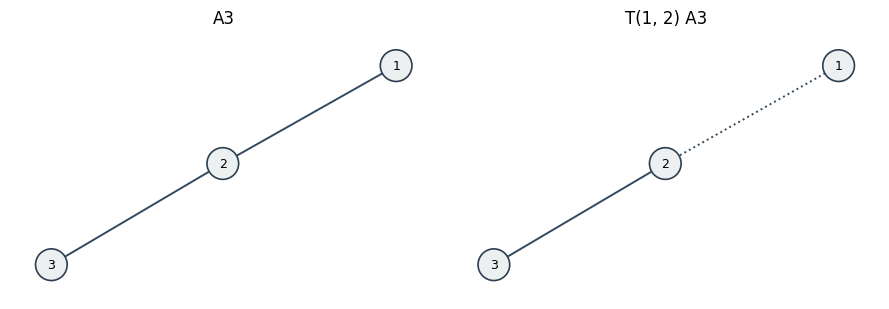

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
A3.draw(ax=axes[0], positions=a3_positions, title="A3")
A3_FLATED.draw(ax=axes[1], positions=a3_positions, title="T(1, 2) A3")
figure.tight_layout()
plt.show()

## 4. Finite Dynkin types and the bounded-flation oracle

**Definition 4.1 (finite Dynkin type).** The finite simply-laced types are the paths $A_n$, the
forks $D_n$, and $E_6$, $E_7$, $E_8$. The full Cartan-Killing list also contains $B_n$, $C_n$,
$F_4$, and $G_2$. Their Cartan matrices are positive definite and have no dotted edge after the
appropriate flations.

**Definition 4.2 (bounded-flation oracle).** `classify()` is an independent exact oracle. It
applies a bounded search of flations and sign inversions to a matrix, keeping integer state. If
the search reaches a solid Dynkin diagram, the oracle reports the type together with a replayable
witness. If exact inertia is not positive definite, it stops before searching. The oracle is not
a proof of the structural theorems below; those theorems have their own certificates.

**Dynkin classification**

**Status:** `CLASSIFIED`

**Inertia**

| positive | negative | zero | rank | signature |
|---:|---:|---:|---:|---:|
| 6 | 0 | 0 | 6 | 6 |

positive definite

**Components**

| labels | Dynkin type |
|---|---|
| 0, 1, 2, 3, 4, 5 | `E_6` |

**Steps:** 0  **Bound:** 36
**Normal form:** E_6

**Flation sequence**

| step | source | target | kind |
|---:|---|---|---|
| - | - | - | none |

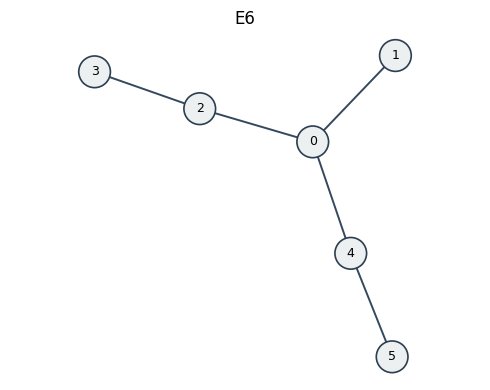

In [8]:
E6 = DynkinType("E", 6).bigraph()
E6_RESULT = E6.classify()
display(Markdown(E6_RESULT.to_markdown()))
display(Markdown(E6_RESULT.witness.to_markdown()))
assert E6_RESULT.status is ClassificationStatus.CLASSIFIED
assert E6_RESULT.components[0].dynkin_type == DynkinType("E", 6)
assert E6_RESULT.verify()
figure, ax = plt.subplots(figsize=(5.0, 4.0))
E6.draw(ax=ax, title="E6")
figure.tight_layout()
plt.show()

## 5. A-type structure: $A_9$

**Definition 5.1 (block-cut tree).** A block is a maximal biconnected subgraph. An articulation
point is a vertex whose removal disconnects its component. The block-cut tree has one node for
each block, one node for each vertex, and an edge when a vertex belongs to a block.

**Theorem 5.2 (A-type criterion).** A connected bigraph is of type $A_n$ exactly when every block
is an A-block and every articulation point belongs to exactly two blocks. An A-block admits a
two-coloring in which cross pairs are solid and same-side pairs are dotted.

We build $A_9$ from path notation. The certificate below is structural: it lists the four blocks,
both sides of each A-block partition, and the articulation points. It is checked independently of
`classify()`.

In [9]:
A9_TEXT = """1--2..3--1
3..4--5--3
3--9--4
5..9
5..6..8..5
4--7"""
A9 = Bigraph.from_paths(A9_TEXT, labels=tuple(range(1, 10)))
display(Markdown("**A9 matrix**\n\n" + A9.matrix.to_markdown(labels=A9.labels)))
A9_CERTIFICATE = A9.a_type_certificate()
assert A9_CERTIFICATE is not None
assert A9_CERTIFICATE.verify(A9)
assert A9_CERTIFICATE.components[0].dynkin_type == DynkinType("A", 9)
display(Markdown(A9_CERTIFICATE.to_markdown()))

**A9 matrix**

|   | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 2 | -1 | -1 | 0 | 0 | 0 | 0 | 0 | 0 |
| 2 | -1 | 2 | 1 | 0 | 0 | 0 | 0 | 0 | 0 |
| 3 | -1 | 1 | 2 | 1 | -1 | 0 | 0 | 0 | -1 |
| 4 | 0 | 0 | 1 | 2 | -1 | 0 | -1 | 0 | -1 |
| 5 | 0 | 0 | -1 | -1 | 2 | 1 | 0 | 1 | 1 |
| 6 | 0 | 0 | 0 | 0 | 1 | 2 | 0 | 1 | 0 |
| 7 | 0 | 0 | 0 | -1 | 0 | 0 | 2 | 0 | 0 |
| 8 | 0 | 0 | 0 | 0 | 1 | 1 | 0 | 2 | 0 |
| 9 | 0 | 0 | -1 | -1 | 1 | 0 | 0 | 0 | 2 |

**A-type certificate**

| component | type | labels | articulation points |
|---|---|---|---|
| C1 | `A_9` | {1, 2, 3, 4, 5, 6, 7, 8, 9} | 3, 4, 5 |

**Blocks**

| component | block | labels | X | Y |
|---|---|---|---|---|
| C1 | B1 | {1, 2, 3} | {2, 3} | {1} |
| C1 | B2 | {3, 4, 5, 9} | {5, 9} | {3, 4} |
| C1 | B3 | {4, 7} | {7} | {4} |
| C1 | B4 | {5, 6, 8} | {5, 6, 8} | {} |

**Figure 3.** $A_9$ and its block-cut tree. The blocks are $\{1,2,3\}$, $\{3,4,5,9\}$, $\{4,7\}$,
and $\{5,6,8\}$; the articulation points $3$, $4$, and $5$ are highlighted. The tree keeps the
articulation points at their $A_9$ coordinates and places each block node at the centroid of its
vertices.

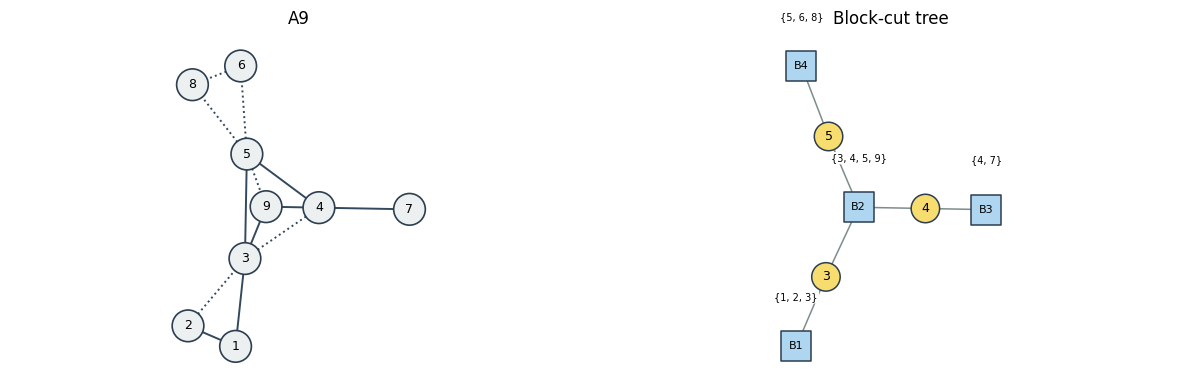

In [10]:
A9_TREE = A9_CERTIFICATE.components[0].tree
A9_POSITIONS = A9.layout()
figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.0))
A9.draw(ax=axes[0], positions=A9_POSITIONS, title="A9")
A9_TREE.draw(ax=axes[1], positions=A9_POSITIONS, title="Block-cut tree")
figure.tight_layout()
plt.show()

## 6. D-type gluing: $D_{13}$

**Definition 6.1 (D-core).** A D-core is an odd cycle of solid and dotted edges, or a two-vertex
double link with one solid and one dotted edge. The parity condition is that the number of dotted
edges is odd.

**Theorem 6.2 (D-core gluing).** Glue one connected positive definite A-type piece onto each core
edge so that consecutive pieces meet only at the shared core vertex and both core endpoints are
internal vertices of their pieces. The resulting positive definite bigraph has type $D_n$, where
$n$ is the number of vertices in the union.

The core below is the odd five-cycle $1-2-3-4-5-1$ with three dotted edges. The pieces are
$A_3$, $A_4$, $A_2$, $A_7$, and $A_2$ in core-edge order. Path text infers labels in first-
appearance order; only the large $A_7$ piece needs an explicit list because its path visits
vertices out of numerical order. The certificate recomputes the gluing and verifies.

In [11]:
D13_CORE_GRAPH = Bigraph.from_paths("1..2--3..4..5--1")
D13_CORE = DCore(EdgeMultiset.from_bigraph(D13_CORE_GRAPH))
D13_PIECES = (
    Bigraph.from_paths("1..2..8..1"),
    Bigraph.from_paths("2--3--6..2\n6--7"),
    Bigraph.from_paths("3..4"),
    Bigraph.from_paths(
        "4--10--5..4\n5..9..4\n9--10\n9--12..13--9\n10--11",
        labels=(4, 5, 9, 10, 11, 12, 13),
    ),
    Bigraph.from_paths("1--5"),
)
D13 = D13_CORE.gluing(D13_PIECES, labels=tuple(range(1, 14)))
assert D13.verify()
assert D13.dynkin_type == DynkinType("D", 13)
assert D13.gluing.classify().components[0].dynkin_type == DynkinType("D", 13)
display(Markdown(D13.to_markdown()))
display(HTML(D13.gluing.matrix.to_html(labels=D13.gluing.labels, collapse=True)))

**D-core gluing certificate**

**Type:** `D_13`  **Core:** (1, 2, 3, 4, 5)

| piece | core edge | labels | A-type |
|---|---|---|---|
| F1 | 1 .. 2 | {1, 2, 8} | `A_3` |
| F2 | 2 -- 3 | {2, 3, 6, 7} | `A_4` |
| F3 | 3 .. 4 | {3, 4} | `A_2` |
| F4 | 4 .. 5 | {4, 5, 9, 10, 11, 12, 13} | `A_7` |
| F5 | 5 -- 1 | {1, 5} | `A_2` |

,1,2,3,4,5,6,7,8,9,10,11,12,13
1,2,1,0,0,-1,0,0,1,0,0,0,0,0
2,1,2,-1,0,0,1,0,1,0,0,0,0,0
3,0,-1,2,1,0,-1,0,0,0,0,0,0,0
4,0,0,1,2,1,0,0,0,1,-1,0,0,0
5,-1,0,0,1,2,0,0,0,1,-1,0,0,0
6,0,1,-1,0,0,2,-1,0,0,0,0,0,0
7,0,0,0,0,0,-1,2,0,0,0,0,0,0
8,1,1,0,0,0,0,0,2,0,0,0,0,0
9,0,0,0,1,1,0,0,0,2,-1,0,-1,-1
10,0,0,0,-1,-1,0,0,0,-1,2,-1,0,0


**Figure 4.** The D-core and the resulting $D_{13}$ bigraph. The five core edges are red and the
five core vertices are filled; every other edge belongs to an A-type piece. Both drawings reuse
the positions computed for $D_{13}$.

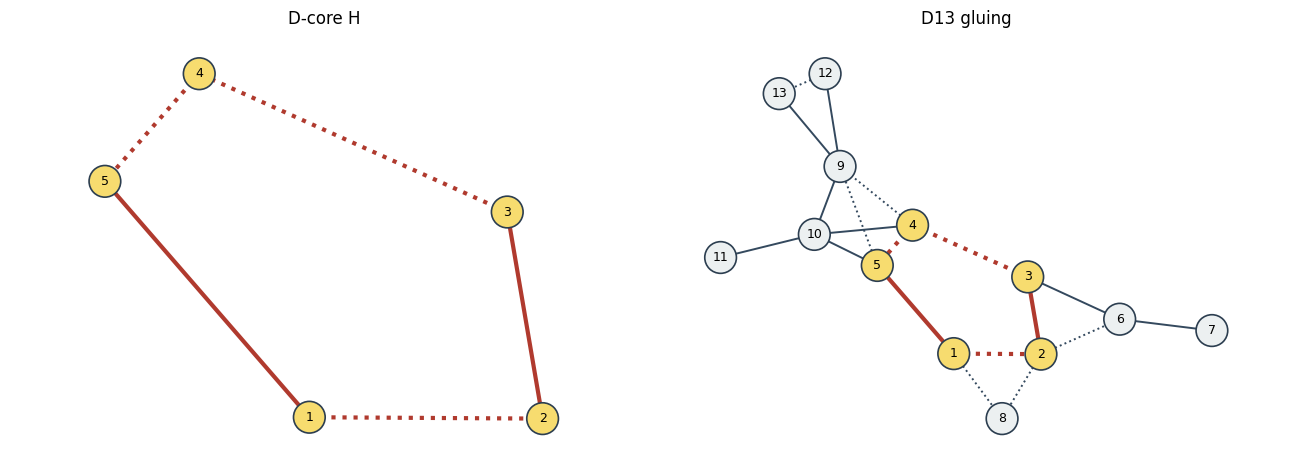

In [12]:
D13_POSITIONS = D13.gluing.layout()
D13_CORE_EDGES = [frozenset((edge.source, edge.target)) for edge in D13_CORE.edges.edges]
figure, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
D13_CORE_GRAPH.draw(
    ax=axes[0],
    positions=D13_POSITIONS,
    title="D-core H",
    highlight_edges=D13_CORE_EDGES,
    highlight_nodes=D13_CORE.labels,
)
D13.gluing.draw(
    ax=axes[1],
    positions=D13_POSITIONS,
    title="D13 gluing",
    highlight_edges=D13_CORE_EDGES,
    highlight_nodes=D13_CORE.labels,
)
figure.tight_layout()
plt.show()

## 7. D-type cyclization: $A_9$ to $D_8$

**Theorem 7.1 (A-cyclization).** Identify two internal vertices $x$ and $y$ of a connected
positive definite A-type bigraph. If the unique shortest $x$-to-$y$ path has an odd number of
dotted edges, the identification produces a positive definite $D_{n-1}$ bigraph.

For $A_9$ we identify vertices $1$ and $6$. The unique shortest path is $1-3-5-6$; it has one
dotted edge. The result has eight vertices and labels $(1, 2, 3, 4, 5, 7, 8, 9)$. The certificate
records the endpoints, the path, the result, and the type.

In [13]:
D8 = A9.a_cyclization(1, 6)
assert D8.verify()
assert D8.path == (1, 3, 5, 6)
assert D8.dynkin_type == DynkinType("D", 8)
assert D8.result.labels == (1, 2, 3, 4, 5, 7, 8, 9)
assert D8.result.classify().components[0].dynkin_type == DynkinType("D", 8)
display(Markdown(D8.to_markdown()))
display(Markdown("**D8 matrix**\n\n" + D8.result.matrix.to_markdown(labels=D8.result.labels)))

**A-cyclization certificate**

| property | value |
|---|---|
| source | {1, 2, 3, 4, 5, 6, 7, 8, 9} |
| identified | 1 = 6 |
| path | 1 -> 3 -> 5 -> 6 |
| result labels | {1, 2, 3, 4, 5, 7, 8, 9} |
| type | `D_8` |

**D8 matrix**

|   | 1 | 2 | 3 | 4 | 5 | 7 | 8 | 9 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 2 | -1 | -1 | 0 | 1 | 0 | 1 | 0 |
| 2 | -1 | 2 | 1 | 0 | 0 | 0 | 0 | 0 |
| 3 | -1 | 1 | 2 | 1 | -1 | 0 | 0 | -1 |
| 4 | 0 | 0 | 1 | 2 | -1 | -1 | 0 | -1 |
| 5 | 1 | 0 | -1 | -1 | 2 | 0 | 1 | 1 |
| 7 | 0 | 0 | 0 | -1 | 0 | 2 | 0 | 0 |
| 8 | 1 | 0 | 0 | 0 | 1 | 0 | 2 | 0 |
| 9 | 0 | 0 | -1 | -1 | 1 | 0 | 0 | 2 |

**Figure 5.** The $A_9$ cyclization. The shortest path $1-3-5-6$ is highlighted on the left; the
identified vertex is labeled $1=6$ on the right. The $D_8$ drawing computes its own layout, so the
identified graph is not merely a subgraph of the $A_9$ picture.

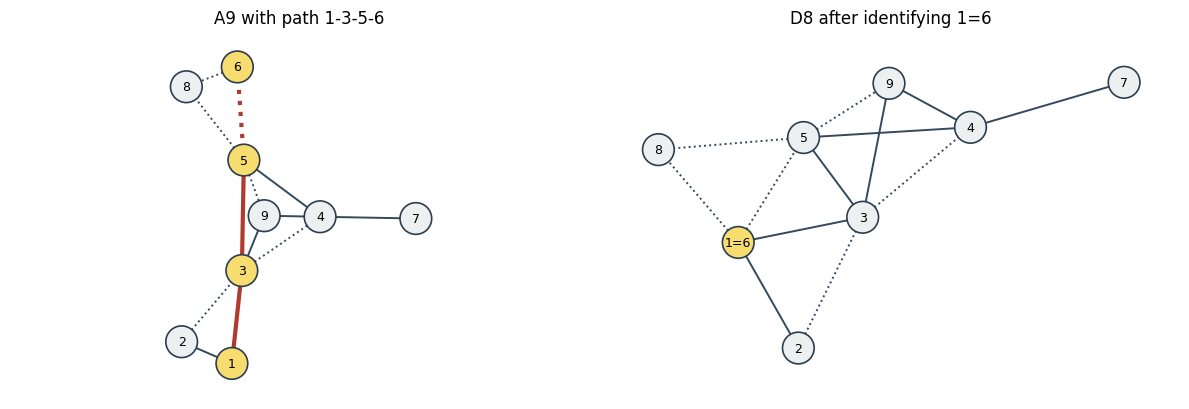

In [14]:
D8_POSITIONS = D8.result.layout()
D8_PATH_EDGES = [
    frozenset((D8.path[index], D8.path[index + 1])) for index in range(len(D8.path) - 1)
]
figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.2))
A9.draw(
    ax=axes[0],
    positions=A9_POSITIONS,
    title="A9 with path 1-3-5-6",
    highlight_edges=D8_PATH_EDGES,
    highlight_nodes=D8.path,
)
D8.result.draw(
    ax=axes[1],
    positions=D8_POSITIONS,
    title="D8 after identifying 1=6",
    display_labels={1: "1=6"},
    highlight_nodes=(1,),
)
figure.tight_layout()
plt.show()

## 8. The boundary table

The table compares the canonical examples with finite, affine, mixed, and non-drawable cases.
The classifier column is the output of the bounded-flation oracle. The certificate column names
only the structural certificates constructed in this notebook. The $2/4$ row is the only one
without a faithful bigraph.

In [15]:
B6 = Bigraph.from_paths(
    """1--2--3..1
3--4..5--3
3.>6
4->6
5->6""",
)
AFFINE_A2 = Bigraph.from_paths("1--2--3--1")

The cases below pair each bigraph with the structural certificate constructed above. The loop
reads the exact inertia, the classifier outcome, and the faithful-bigraph predicate directly from
the public values.

In [16]:
BOUNDARY_CASES = (
    ("A9", A9, "A-type"),
    ("D13", D13.gluing, "D-core"),
    ("D8", D8.result, "A-cyclization"),
    ("E6", E6, "none"),
    ("mixed B6", B6, "none"),
    ("affine A2", AFFINE_A2, "none"),
    ("2/4 matrix", Bigraph(bad, (1, 2)), "none"),
)
BOUNDARY_ROWS = {}
BOUNDARY_LINES = [
    "| case | inertia | classifier outcome | faithful bigraph | certificate |",
    "|---|---|---|---|---|",
]
for name, bigraph, certificate in BOUNDARY_CASES:
    result = bigraph.classify()
    outcome = (
        result.components[0].dynkin_type.name
        if result.status is ClassificationStatus.CLASSIFIED
        else result.status.name
    )
    inertia = bigraph.matrix.inertia
    faithful = "yes" if bigraph.matrix.has_faithful_bigraph else "no"
    BOUNDARY_ROWS[name] = (outcome, faithful, certificate)
    BOUNDARY_LINES.append(
        f"| {name} | ({inertia.positive}, {inertia.negative}, {inertia.zero}) "
        f"| `{outcome}` | {faithful} | {certificate} |",
    )
display(Markdown("\n".join(BOUNDARY_LINES)))
assert BOUNDARY_ROWS["A9"] == ("A_9", "yes", "A-type")
assert BOUNDARY_ROWS["D13"] == ("D_13", "yes", "D-core")
assert BOUNDARY_ROWS["D8"] == ("D_8", "yes", "A-cyclization")
assert BOUNDARY_ROWS["E6"] == ("E_6", "yes", "none")
assert BOUNDARY_ROWS["mixed B6"] == ("B_6", "yes", "none")
assert BOUNDARY_ROWS["affine A2"] == ("NOT_POSITIVE_DEFINITE", "yes", "none")
assert BOUNDARY_ROWS["2/4 matrix"] == ("NOT_ADMISSIBLE", "no", "none")

| case | inertia | classifier outcome | faithful bigraph | certificate |
|---|---|---|---|---|
| A9 | (9, 0, 0) | `A_9` | yes | A-type |
| D13 | (13, 0, 0) | `D_13` | yes | D-core |
| D8 | (8, 0, 0) | `D_8` | yes | A-cyclization |
| E6 | (6, 0, 0) | `E_6` | yes | none |
| mixed B6 | (6, 0, 0) | `B_6` | yes | none |
| affine A2 | (2, 0, 1) | `NOT_POSITIVE_DEFINITE` | yes | none |
| 2/4 matrix | (1, 1, 0) | `NOT_ADMISSIBLE` | no | none |

## Exercises

1. Prove that a flation preserves the symmetrizer and the inertia. Which row and column operations
   realize the inverse flation?
2. Show that a positive definite quasi-Cartan matrix has no off-diagonal pair with both
   magnitudes at least two. Where is the principal-minor argument used?
3. Draw the block-cut tree of the disjoint union $A_2 \sqcup A_3$. Why does the A-type certificate
   have one component per connected component?
4. Verify that the D-core cycle condition is parity, not orientation. What happens if one solid
   and one dotted core edge are swapped?
5. Explain why the A-cyclization path must have an odd number of dotted edges. Trace the
   identification on the $D_8$ matrix.
6. Change one lab parameter at a time. Which invariants survive, and which certificate fields
   change?

## Parameter labs

The canonical tour above is fixed. Each lab below exposes one input. Change the input and rerun
the cell; the checks assert invariants or certificate validity rather than one hardcoded type.

**Layout lab.** Choose `planar`, `spring`, or `circular`, and set `ITERATIONS` for the spring
policy. The `kamada_kawai` policy is also available when SciPy is installed. The automatic policy
uses Kamada-Kawai for connected graphs when SciPy is available; otherwise it uses the seeded,
energy-based spring layout with 10000 iterations by default. Layout distances ignore the signed
solid/dotted weights and use unweighted adjacency. A planar graph with a $K_4$ block, such as
$A_9$, starts from a planar embedding and is refined by the same spring layout. `planar` remains
an explicit option.

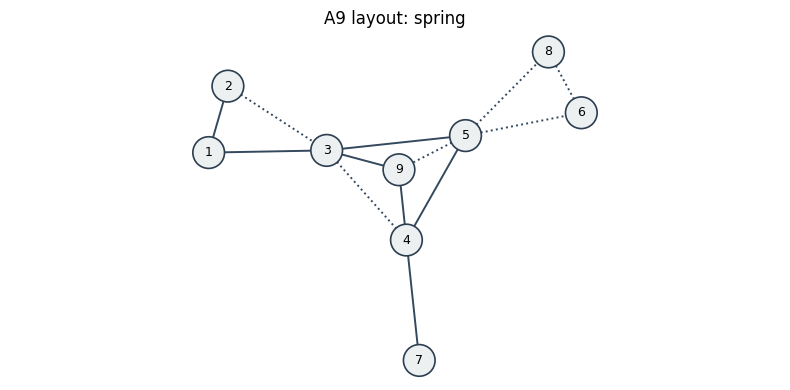

In [17]:
LAYOUT = "spring"
ITERATIONS = 10000
LAB_POSITIONS = A9.layout(layout=LAYOUT, seed=7, iterations=ITERATIONS)
assert set(LAB_POSITIONS) == set(A9.labels)
assert A9.layout(layout=LAYOUT, seed=7, iterations=ITERATIONS) == LAB_POSITIONS
figure, ax = plt.subplots(figsize=(8.0, 4.0))
A9.draw(
    ax=ax,
    layout=LAYOUT,
    seed=7,
    iterations=ITERATIONS,
    title=f"A9 layout: {LAYOUT}",
)
figure.tight_layout()
plt.show()

**Path lab.** Edit `PATHS` and rerun. The constructor infers label order from first appearance;
the checks require a connected positive definite path graph with a classified outcome.

|   | 1 | 2 | 3 | 4 |
|---|---:|---:|---:|---:|
| 1 | 2 | -1 | 0 | 0 |
| 2 | -1 | 2 | -1 | 0 |
| 3 | 0 | -1 | 2 | -1 |
| 4 | 0 | 0 | -1 | 2 |

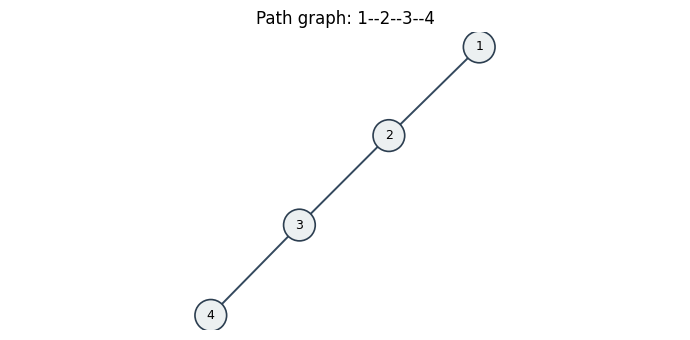

In [18]:
PATHS = "1--2--3--4"
LAB_GRAPH = Bigraph.from_paths(PATHS)
display(Markdown(LAB_GRAPH.matrix.to_markdown(labels=LAB_GRAPH.labels)))
assert LAB_GRAPH.matrix.inertia.is_positive_definite
assert LAB_GRAPH.matrix.inertia.positive == LAB_GRAPH.dimension
assert LAB_GRAPH.classify().status is ClassificationStatus.CLASSIFIED
figure, ax = plt.subplots(figsize=(7.0, 3.5))
LAB_GRAPH.draw(ax=ax, title=f"Path graph: {PATHS}")
figure.tight_layout()
plt.show()

**Flation lab.** Edit `SOURCE` and `TARGET`. The checks require preserved inertia and a classified
positive definite result, without naming the original type.

|   | 1 | 2 | 3 |
|---|---:|---:|---:|
| 1 | 2 | 1 | 0 |
| 2 | 1 | 2 | -1 |
| 3 | 0 | -1 | 2 |

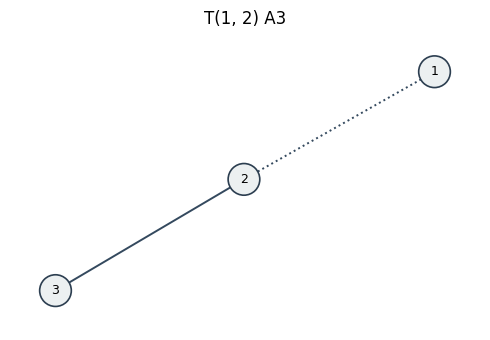

In [19]:
SOURCE, TARGET = 1, 2
LAB_FLATED = A3.flation(SOURCE, TARGET)
assert LAB_FLATED.matrix.inertia == A3.matrix.inertia
assert LAB_FLATED.classify().status is ClassificationStatus.CLASSIFIED
display(Markdown(LAB_FLATED.matrix.to_markdown(labels=LAB_FLATED.labels)))
figure, ax = plt.subplots(figsize=(5.0, 3.5))
LAB_FLATED.draw(ax=ax, positions=a3_positions, title=f"T({SOURCE}, {TARGET}) A3")
figure.tight_layout()
plt.show()

**Cyclization lab.** Edit `X` and `Y`. The checks require a valid certificate, one fewer vertex,
and a positive definite result; they do not hardcode $D_8$.

In [20]:
X, Y = 1, 6
LAB_CYCLIZATION = A9.a_cyclization(X, Y)
assert LAB_CYCLIZATION.verify()
assert LAB_CYCLIZATION.result.dimension == A9.dimension - 1
assert LAB_CYCLIZATION.result.matrix.inertia.is_positive_definite
display(Markdown(LAB_CYCLIZATION.to_markdown()))

**A-cyclization certificate**

| property | value |
|---|---|
| source | {1, 2, 3, 4, 5, 6, 7, 8, 9} |
| identified | 1 = 6 |
| path | 1 -> 3 -> 5 -> 6 |
| result labels | {1, 2, 3, 4, 5, 7, 8, 9} |
| type | `D_8` |

## References

1. N. Bourbaki, *Lie Groups and Lie Algebras*, Chapters 4-6, Springer.
2. V. Kac, *Infinite-Dimensional Lie Algebras*, 3rd edition, Cambridge University Press.
3. M. Barot, "Geometric invariants of quivers and quasi-Cartan matrices", and the A/D structural
   constructions used in the certificate definitions.
4. DynkinLab source and API reference: <https://github.com/knkillname/dynkinlab>.

## Final checks

The final cell replays the canonical certificates one last time and reports the installed package
version. If any assertion fails, the notebook stops before this message.

In [21]:
assert A9_CERTIFICATE is not None
assert A9_CERTIFICATE.verify(A9)
assert D13.verify()
assert D8.verify()
assert A3_FLATED.matrix.inertia == A3.matrix.inertia == Inertia(3, 0, 0)
assert BOUNDARY_ROWS["A9"] == ("A_9", "yes", "A-type")
assert BOUNDARY_ROWS["2/4 matrix"] == ("NOT_ADMISSIBLE", "no", "none")
print(f"DynkinLab {dynkinlab.__version__}")
print("All certificates verified.")

DynkinLab 0.0.1
All certificates verified.
